# Google Cloud CMIP6 Public Data: Basic Python Example

This notebooks shows how to query the catalog and load the data using python

In [1]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis

In [2]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [3]:
plt.rcParams['figure.figsize'] = 12, 6

## Browse Catalog

The data catatalog is stored as a CSV file. Here we read it with Pandas.

In [4]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


In [5]:
df["activity_id"].unique()

array(['HighResMIP', 'CMIP', 'CFMIP', 'ScenarioMIP', 'AerChemMIP',
       'RFMIP', 'FAFMIP', 'DAMIP', 'LUMIP', 'CDRMIP', 'GMMIP', 'C4MIP',
       'OMIP', 'PMIP', 'LS3MIP', 'DCPP', 'PAMIP', 'ISMIP6'], dtype=object)

In [6]:
df["institution_id"].unique()

array(['CMCC', 'EC-Earth-Consortium', 'MOHC', 'ECMWF', 'NOAA-GFDL',
       'IPSL', 'E3SM-Project', 'CNRM-CERFACS', 'NASA-GISS', 'BCC',
       'MIROC', 'AWI', 'NCAR', 'MRI', 'CCCma', 'SNU', 'CAS', 'INM',
       'NUIST', 'HAMMOZ-Consortium', 'CAMS', 'MPI-M', 'DKRZ', 'DWD', 'UA',
       'NIMS-KMA', 'NCC', 'FIO-QLNM', 'KIOST', 'CSIRO-ARCCSS', 'CSIRO',
       'CCCR-IITM', 'THU', 'AS-RCEC', 'NERC', 'RUBISCO'], dtype=object)

The columns of the dataframe correspond to the CMI6 controlled vocabulary. A beginners' guide to these terms is available in [this document](https://docs.google.com/document/d/1yUx6jr9EdedCOLd--CPdTfGDwEwzPpCF6p1jRmqx-0Q).

Here we filter the data to find monthly surface air temperature for historical experiments.

In [7]:
df_ta = df.query("activity_id=='CMIP' & table_id == 'Omon' & variable_id == 'thetao' & experiment_id == 'historical'")
df_ta

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
9979,CMIP,NOAA-GFDL,GFDL-CM4,historical,r1i1p1f1,Omon,thetao,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-CM4/histo...,NaN,20180701
9980,CMIP,NOAA-GFDL,GFDL-CM4,historical,r1i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-CM4/histo...,NaN,20180701
22329,CMIP,IPSL,IPSL-CM6A-LR,historical,r8i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/IPSL/IPSL-CM6A-LR/histor...,NaN,20180803
23141,CMIP,IPSL,IPSL-CM6A-LR,historical,r9i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/IPSL/IPSL-CM6A-LR/histor...,NaN,20180803
23196,CMIP,IPSL,IPSL-CM6A-LR,historical,r28i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/IPSL/IPSL-CM6A-LR/histor...,NaN,20180803
...,...,...,...,...,...,...,...,...,...,...,...
517086,CMIP,MIROC,MIROC-ES2L,historical,r26i1p1f2,Omon,thetao,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517136,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517137,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,thetao,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517158,CMIP,MIROC,MIROC-ES2L,historical,r25i1p1f2,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317


Now we do further filtering to find just the models from NCAR.

In [8]:
df_ta["institution_id"].value_counts()

institution_id
MIROC                  112
EC-Earth-Consortium     84
NASA-GISS               72
NCC                     72
CCCma                   53
NCAR                    40
CNRM-CERFACS            39
IPSL                    34
CSIRO                   29
MOHC                    25
MPI-M                   21
MRI                     12
INM                     11
CAS                      9
E3SM-Project             7
AWI                      6
BCC                      6
NUIST                    5
NOAA-GFDL                4
FIO-QLNM                 3
THU                      3
CMCC                     3
CAMS                     3
CSIRO-ARCCSS             3
HAMMOZ-Consortium        3
UA                       2
SNU                      1
AS-RCEC                  1
NIMS-KMA                 1
Name: count, dtype: int64

In [9]:
df_ta_ncar = df_ta.query('institution_id == "MIROC"')
df_ta_ncar

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
64259,CMIP,MIROC,MIROC6,historical,r5i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC6/historical/...,NaN,20190311
65047,CMIP,MIROC,MIROC6,historical,r8i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC6/historical/...,NaN,20190311
65276,CMIP,MIROC,MIROC6,historical,r9i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC6/historical/...,NaN,20190311
65405,CMIP,MIROC,MIROC6,historical,r1i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC6/historical/...,NaN,20190311
65436,CMIP,MIROC,MIROC6,historical,r10i1p1f1,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC6/historical/...,NaN,20190311
...,...,...,...,...,...,...,...,...,...,...,...
517086,CMIP,MIROC,MIROC-ES2L,historical,r26i1p1f2,Omon,thetao,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517136,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517137,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,thetao,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517158,CMIP,MIROC,MIROC-ES2L,historical,r25i1p1f2,Omon,thetao,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317


## Load Data

Now we will load a single store using gcsfs, zarr, and xarray.

In [10]:
# this only needs to be created once
gcs = gcsfs.GCSFileSystem(token='anon')

# get the path to a specific zarr store (the first one from the dataframe above)
zstore = df_ta_ncar.iloc[0].zstore

# create a mutable-mapping-style interface to the store
mapper = gcs.get_mapper(zstore)

# open it using xarray and zarr
ds = xr.open_zarr(mapper, consolidated=True)
ds

<xarray.Dataset> Size: 47GB
Dimensions:             (y: 256, x: 360, time: 1980, lev: 63, vertices: 4,
                         bnds: 2)
Coordinates:
  * y                   (y) float64 2kB -88.0 -85.75 -85.25 ... 150.5 152.4
  * x                   (x) float64 3kB 0.5 1.5 2.5 3.5 ... 357.5 358.5 359.5
    latitude            (y, x) float32 369kB ...
    longitude           (y, x) float32 369kB ...
  * time                (time) datetime64[ns] 16kB 1850-01-16T12:00:00 ... 20...
  * lev                 (lev) float64 504B 1.0 3.5 7.0 ... 6.87e+03 7.25e+03
    lev_bnds            (lev, bnds) float64 1kB ...
    sigma_bnds          (lev, bnds) float64 1kB ...
    time_bnds           (time, bnds) datetime64[ns] 32kB ...
    x_bnds              (x, bnds) float64 6kB ...
    y_bnds              (y, bnds) float64 4kB ...
    zlev_bnds           (lev, bnds) float64 1kB ...
Dimensions without coordinates: vertices, bnds
Data variables:
    depth               (y, x) float32 369kB ...
    depth_c             float64 8B ...
    eta                 (time, y, x) float32 730MB ...
    nsigma              int32 4B ...
    sigma               (lev) float64 504B ...
    thetao              (time, lev, y, x) float32 46GB ...
    vertices_latitude   (y, x, vertices) float32 1MB ...
    vertices_longitude  (y, x, vertices) float32 1MB ...
    zlev                (lev) float64 504B ...
Attributes: (12/45)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  43829.0
    cmor_version:           3.3.2
    ...                     ...
    table_info:             Creation Date:(06 November 2018) MD5:0728c79344e0...
    title:                  MIROC6 output prepared for CMIP6
    tracking_id:            hdl:21.14100/d2417e61-8003-4417-82a5-28e850d2b0eb...
    variable_id:            thetao
    variant_label:          r5i1p1f1
    status:                 2019-11-08;created;by nhn2@columbia.edu

## Ocean warming in `thetao`

`thetao` is ocean potential temperature (°C). It has 4 dimensions: `time × lev × y × x`, where `lev` is depth in metres.
The full dataset is 47 GB, so we only load two 5-year periods and compare them:

- **early**: 1850–1854
- **late**: 2010–2014

This downloads about 1 GB and takes a few minutes.

In [11]:
# ocean cell area (m²), used to weight averages so big cells count more than small ones
area_store = df.query("source_id == 'MIROC6' & variable_id == 'areacello' & experiment_id == 'historical'").zstore.values[0]
area = xr.open_zarr(gcs.get_mapper(area_store), consolidated=True).areacello

# average each period over time -> (lev, y, x)
early = ds.thetao.sel(time=slice('1850', '1854')).mean('time').load()
late  = ds.thetao.sel(time=slice('2010', '2014')).mean('time').load()
warming = late - early
# MIROC6's last level (7250 m) is not real ocean: it has values where the levels above it are empty. Drop it.
warming = warming.sel(lev=slice(0, 7000))

def on_map(da):
    """On MIROC6's grid, x is not longitude: longitude = x + 60. Shift it so the map lines up."""
    return da.assign_coords(x=(da.x + 60) % 360).sortby('x')

### Plot 1: Sea-surface temperature, 2010–2014

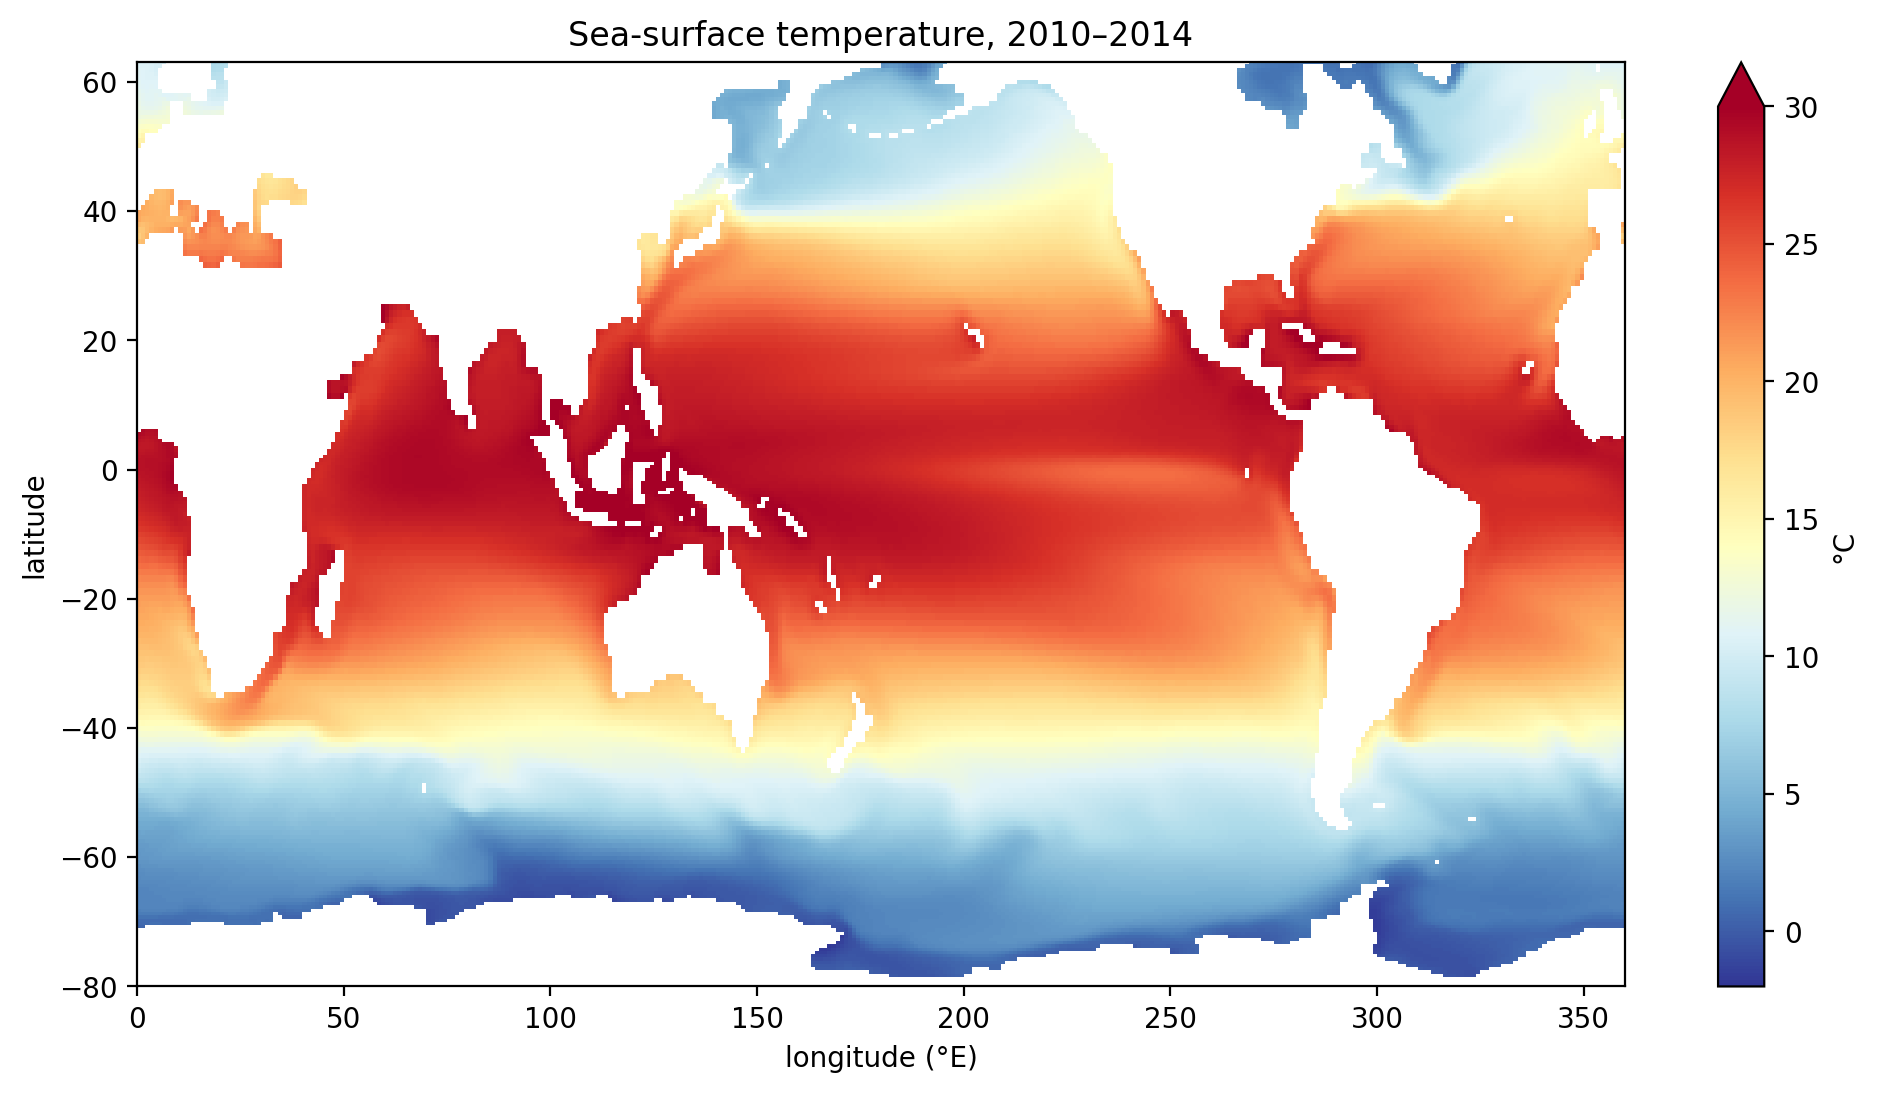

In [12]:

#lev=0 is the top depth level of thetao, centred at 1 m. So "sea surface" in the titles means "sea water potential temperature in the top layer of the model ocean."
on_map(late.isel(lev=0)).plot(cmap='RdYlBu_r', vmin=-2, vmax=30, cbar_kwargs={'label': '°C'})
plt.ylim(-80, 63)   # north of ~63°N the grid bends toward the poles, so y stops being latitude
plt.xlabel('longitude (°E)')
plt.ylabel('latitude')
plt.title('Sea-surface temperature, 2010–2014');

### Plot 2: How much has the surface warmed?
Red = warmer than 1850–1854, blue = cooler.

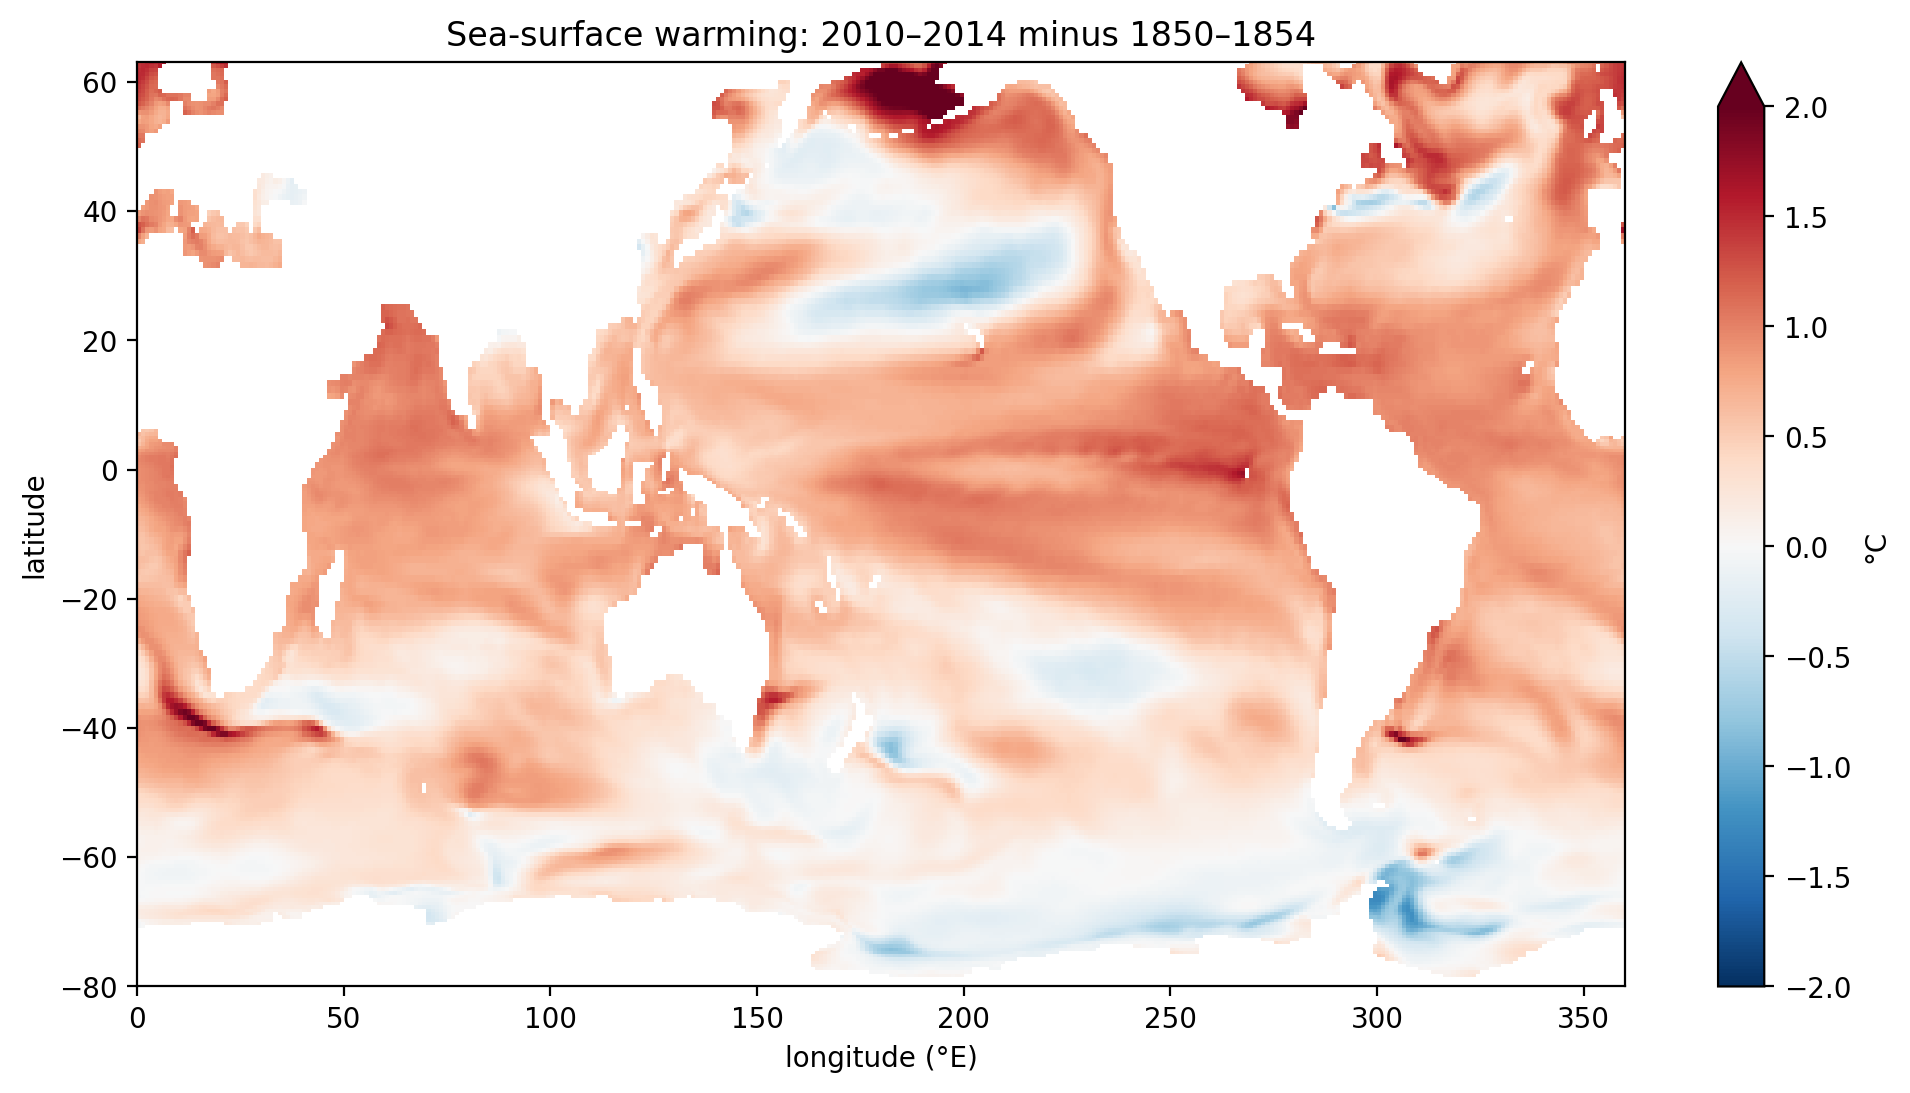

In [13]:
on_map(warming.isel(lev=0)).plot(cmap='RdBu_r', vmin=-2, vmax=2, cbar_kwargs={'label': '°C'})
plt.ylim(-80, 63)
plt.xlabel('longitude (°E)')
plt.ylabel('latitude')
plt.title('Sea-surface warming: 2010–2014 minus 1850–1854');

### Plot 3: Warming at each depth
The area-weighted global average of the warming at each depth level.

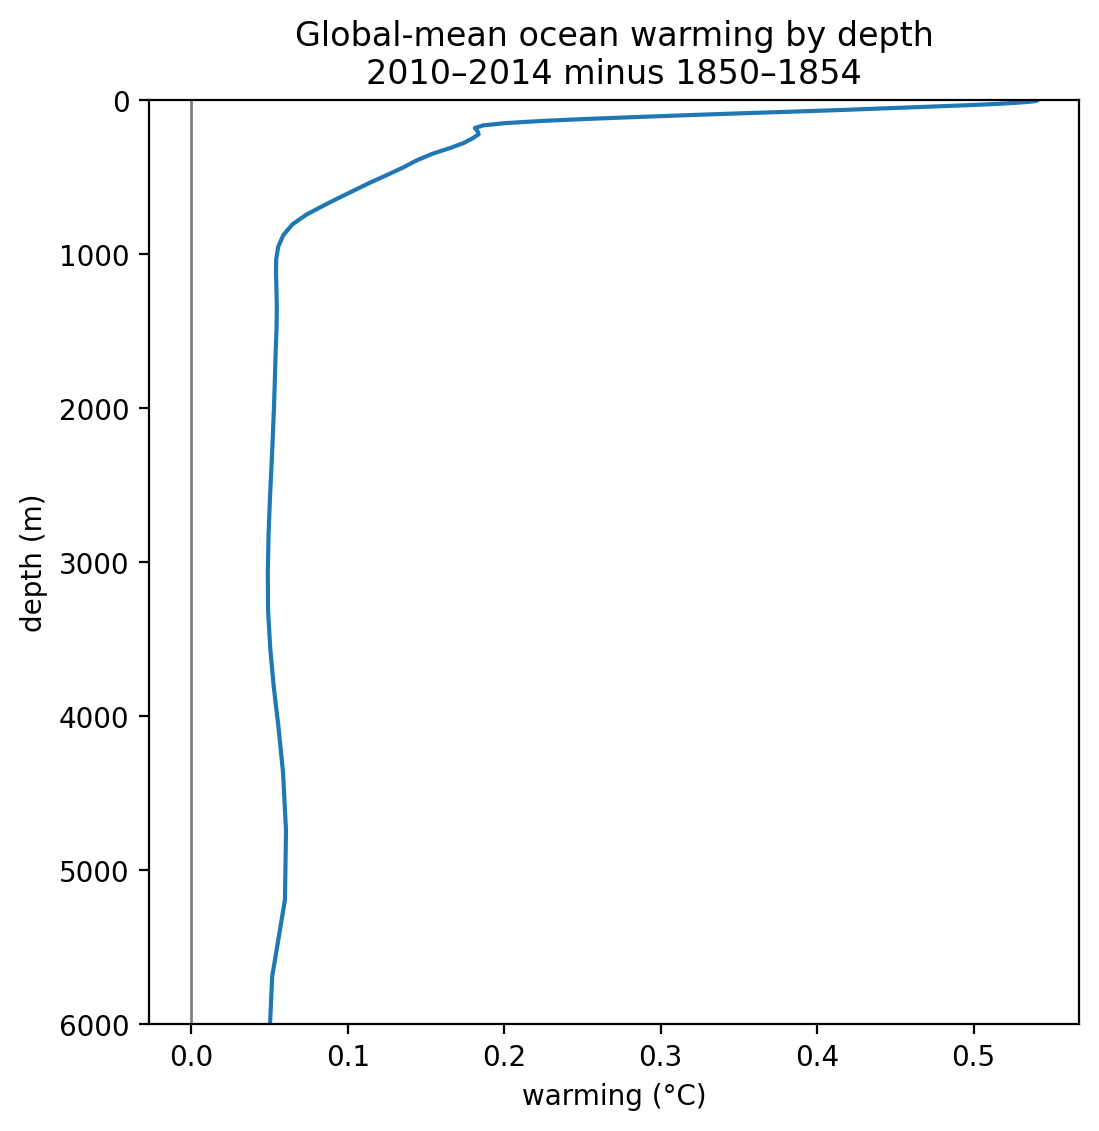

In [14]:
profile = warming.weighted(area.fillna(0)).mean(['y', 'x'])

plt.figure(figsize=(6, 6))
plt.plot(profile, profile.lev)
plt.axvline(0, color='gray', linewidth=1)
plt.ylim(6000, 0)   # surface at the top
plt.xlabel('warming (°C)')
plt.ylabel('depth (m)')
plt.title('Global-mean ocean warming by depth\n2010–2014 minus 1850–1854');

### Plot 4: Warming by latitude and depth
The average over all longitudes, so each column is one latitude band. Gray is the sea floor.

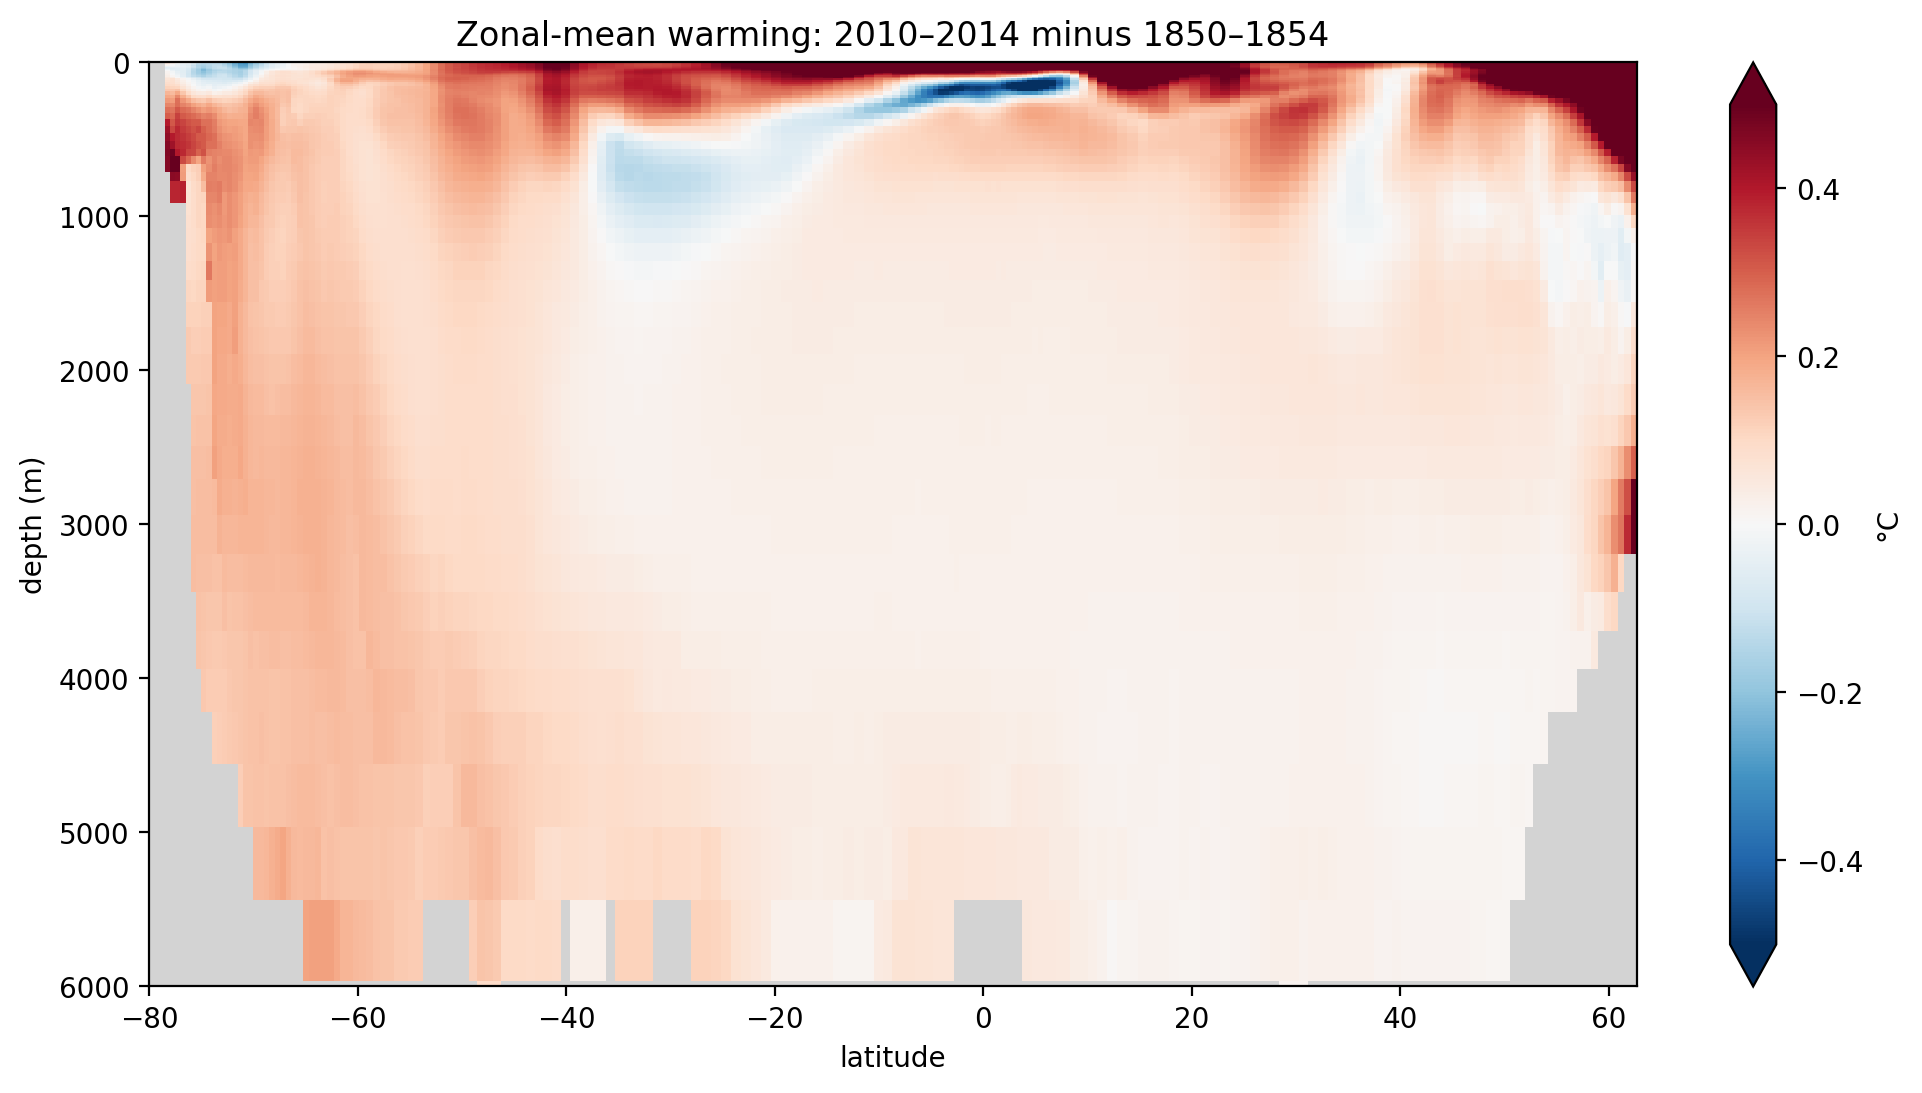

In [15]:
section = warming.mean('x').sel(y=slice(-80, 63))   # south of 63°N, y is latitude

ax = plt.axes(facecolor='lightgray')
section.plot(ax=ax, y='lev', yincrease=False, cmap='RdBu_r', vmin=-0.5, vmax=0.5, cbar_kwargs={'label': '°C'})
plt.ylim(6000, 0)
plt.xlabel('latitude')
plt.ylabel('depth (m)')
plt.title('Zonal-mean warming: 2010–2014 minus 1850–1854');

### Plot 5: How much heat has the ocean absorbed?
Turn the warming into energy: heat = density × heat capacity × warming × volume, added up over each layer.
The unit is zettajoules (1 ZJ = 10²¹ J).

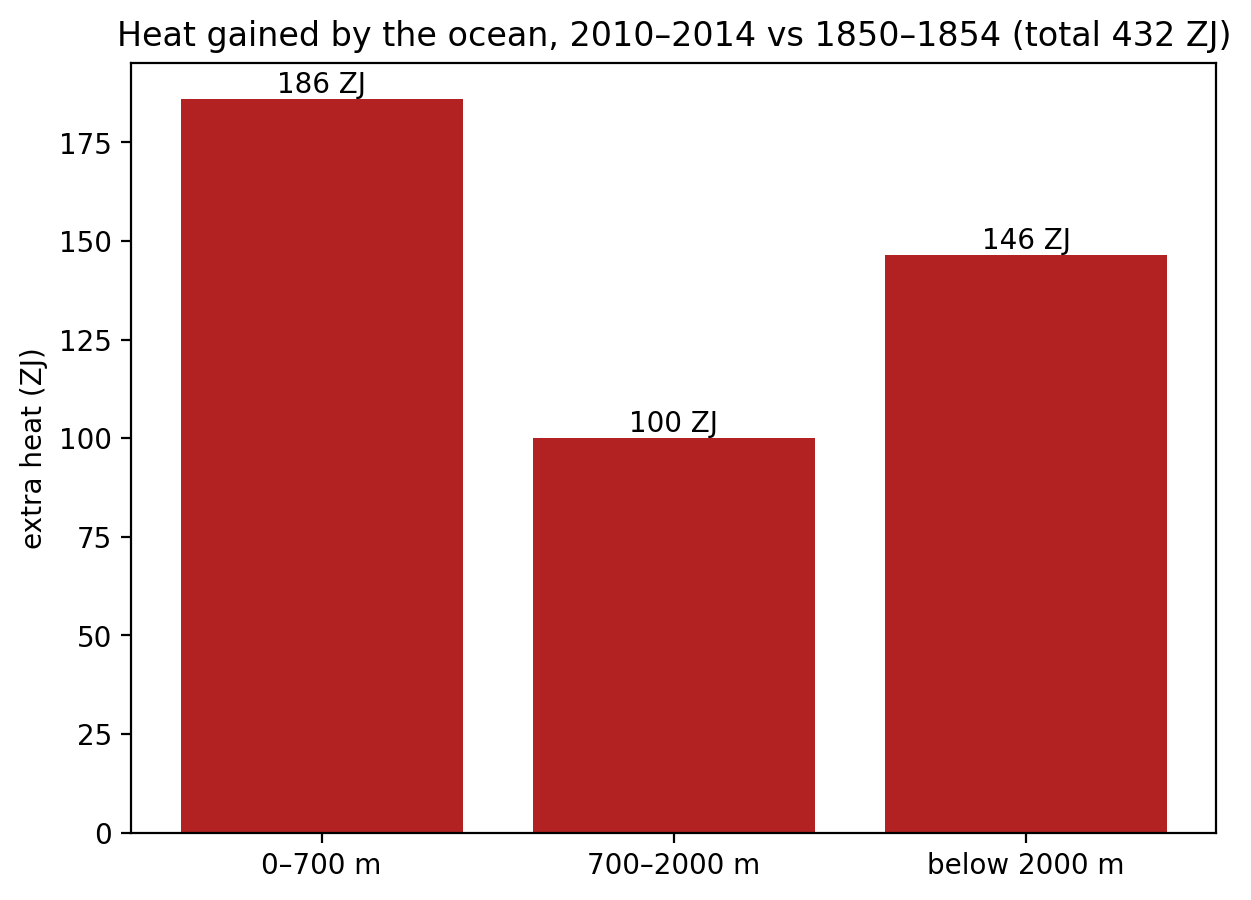

In [16]:
RHO_CP = 1025 * 3990                                             # sea-water density (kg/m³) × heat capacity (J/kg/°C)
thickness = (ds.lev_bnds[:, 1] - ds.lev_bnds[:, 0]).load()       # thickness of each depth layer (m)
heat = (warming * area * thickness).sum(['y', 'x']) * RHO_CP / 1e21   # extra heat in each layer (ZJ)

layers = {
    '0–700 m':        heat.where(heat.lev < 700).sum(),
    '700–2000 m':     heat.where((heat.lev >= 700) & (heat.lev < 2000)).sum(),
    'below 2000 m':   heat.where(heat.lev >= 2000).sum(),
}
values = [float(v) for v in layers.values()]

plt.figure(figsize=(7, 5))
bars = plt.bar(layers.keys(), values, color='firebrick')
plt.bar_label(bars, fmt='%.0f ZJ')
plt.ylabel('extra heat (ZJ)')
plt.title(f'Heat gained by the ocean, 2010–2014 vs 1850–1854 (total {sum(values):.0f} ZJ)');

### Plot 6: Seasonal cycle at different depths
Monthly `thetao` averaged over a box in the North Atlantic (40–50°N, 40–30°W), then averaged by calendar month over 2010–2014.
This loads the 2010–2014 data again (about 0.5 GB), because this time we keep the months instead of averaging them.

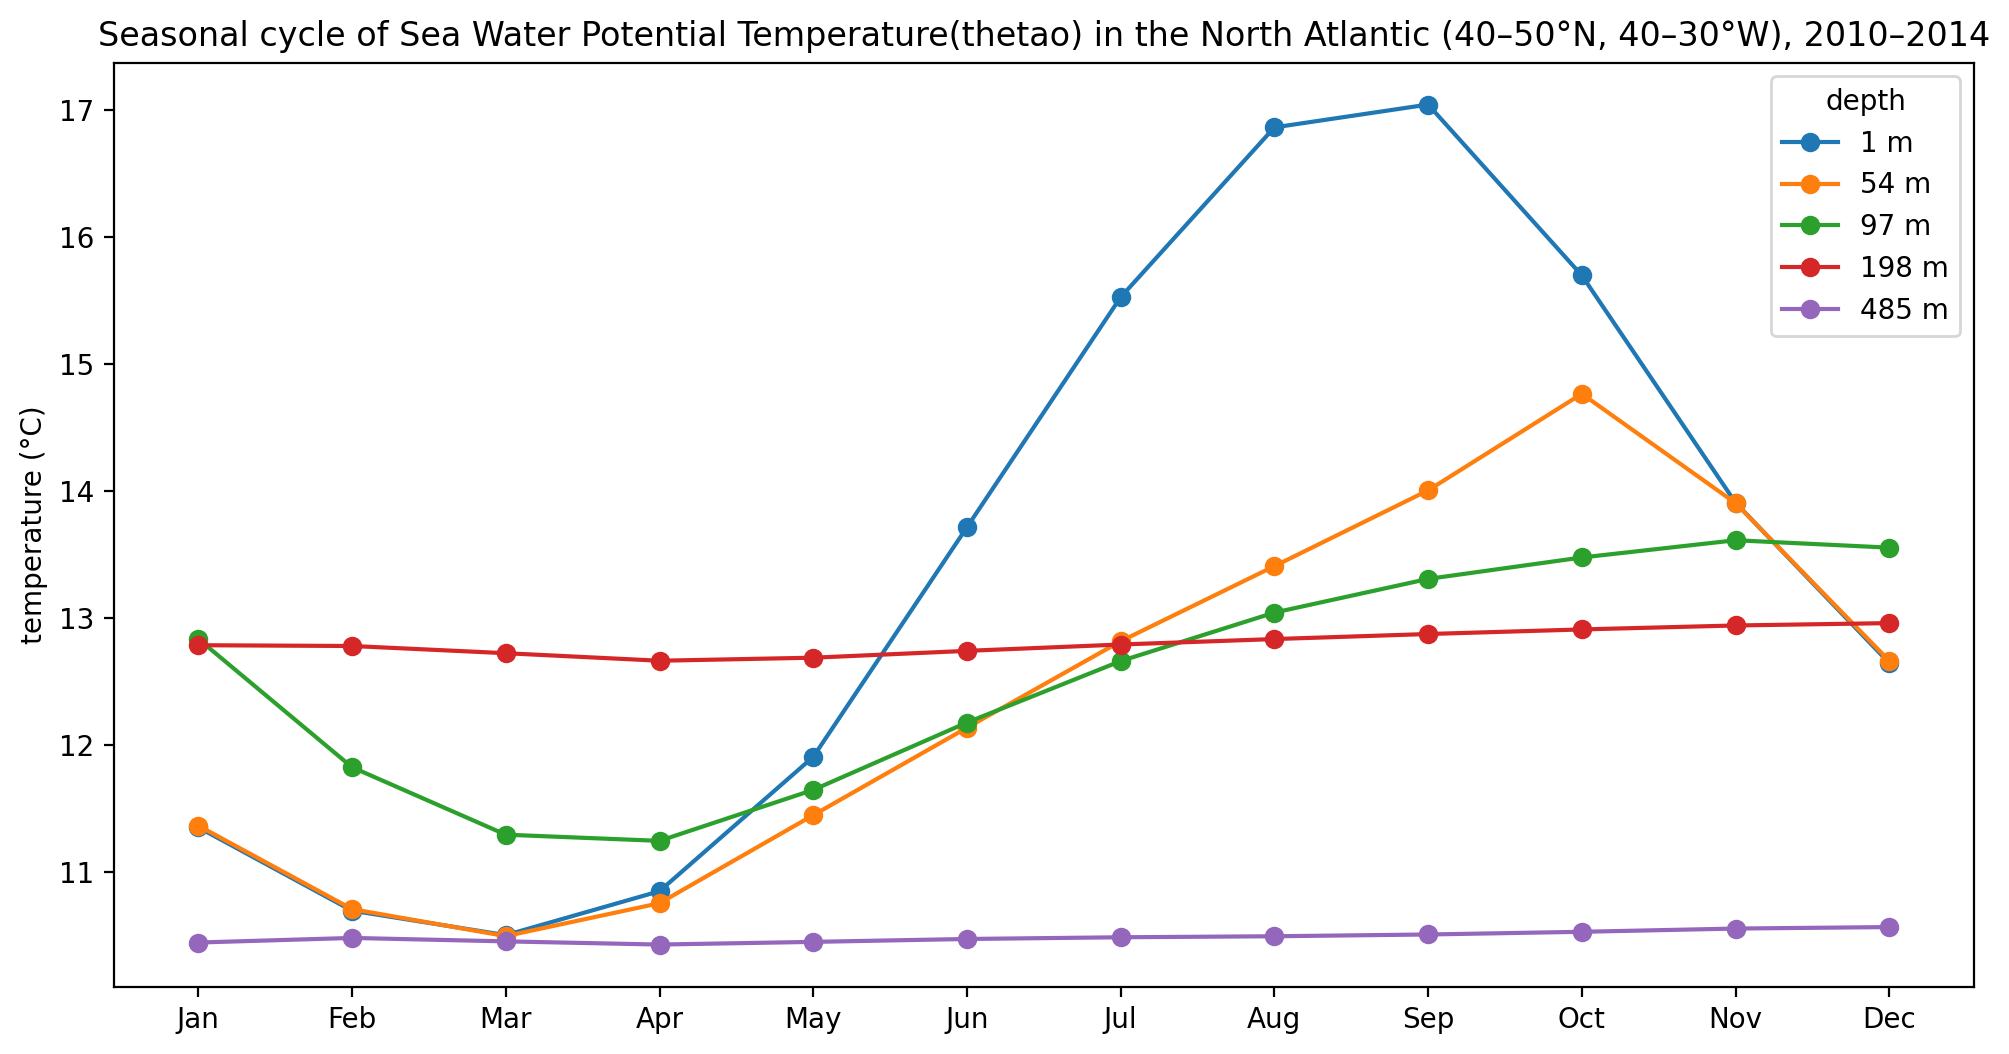

In [17]:
# grid cells inside the box (MIROC6 has 2-D latitude/longitude, so we use a mask)
box = (ds.latitude >= 40) & (ds.latitude <= 50) & (ds.longitude >= 320) & (ds.longitude <= 330)

region = ds.thetao.sel(time=slice('2010', '2014')).where(box).weighted(area.fillna(0)).mean(['y', 'x']).load()   # (time, lev)
monthly = region.groupby('time.month').mean()                                                                    # (month, lev)

for depth in [1, 50, 100, 200, 500]:
    line = monthly.sel(lev=depth, method='nearest')
    plt.plot(line.month, line, marker='o', label=f'{float(line.lev):.0f} m')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.ylabel('temperature (°C)')
plt.legend(title='depth')
plt.title('Seasonal cycle of Sea Water Potential Temperature(thetao) in the North Atlantic (40–50°N, 40–30°W), 2010–2014');